# Fase 3.6 — Robustez e viés de seleção

**Objetivo:** verificar se as duas conclusões principais da regressão sobrevivem
quando se mudam as escolhas de método:

- **A.** O concurso público tem um efeito próprio sobre o estouro, além do porte (+8,5 p.p. no modelo principal).
- **B.** Os contratos de 2021 estouram mais que os de 2019, mesmo com todos os controles (+16,9 p.p.).

Cada variação refaz o modelo completo (modelo 3 do notebook 05) mudando **uma** escolha.
Se os efeitos mantiverem o sinal e uma magnitude parecida, as conclusões são robustas.

| Variação | O que muda | Por que testar |
| --- | --- | --- |
| Principal | Igual ao notebook 05 | Referência |
| Com 2018 | Janela 2018–2022 | 2018 foi excluído por ser ano de transição do registo (D6) |
| Estouro acima de 5% | Estouro só se o custo final passar 5% do contratado | Ver se o efeito não vem de estouros mínimos |
| Sem megaprojetos | Exclui contratos acima de 5 milhões de euros | Ver se poucos contratos enormes puxam o resultado (D11) |
| Base de modificações | Estouro = preço final da última modificação acima do contratado; **todos** os contratos, com ou sem fecho | Medida independente do preço efetivo, e sem depender de o fecho ter sido registado |

No fim, um modelo do **viés de seleção**: quais contratos têm o fecho registado?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

RAIZ = Path("..")
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

e = pd.read_parquet(RAIZ / "data" / "processed" / "empreitadas.parquet")
PROCEDIMENTOS = {"Ajuste Direto Regime Geral": "Ajuste direto",
                 "Consulta Prévia": "Consulta prévia",
                 "Concurso público": "Concurso público"}
e["procedimento"] = e["tipoprocedimento"].map(PROCEDIMENTOS).fillna("Outros")


def agrupar_raros(serie, minimo=300, rotulo="outros"):
    contagem = serie.value_counts()
    return serie.where(serie.isin(contagem[contagem >= minimo].index), rotulo).fillna(rotulo)


def preparar(df, y):
    """Variáveis explicativas do modelo completo; y = nome da coluna 0/1 a explicar."""
    m = df[df["preco_contratual_2021"].gt(0) & df["prazoExecucao"].gt(0)].copy()
    m["y"] = m[y].astype(int)
    m["log_preco"] = np.log10(m["preco_contratual_2021"].astype(float))
    m["log_prazo"] = np.log10(m["prazoExecucao"].astype(float))
    m["cpv"] = agrupar_raros(m["cpv_divisao"])
    m["distrito"] = agrupar_raros(m["local_distrito"])
    m["ano"] = m["ano_celebracao"].astype(str)
    m["concorrencia"] = (pd.cut(m["concorrentes"], [0, 1, 3, 5, np.inf], labels=["1", "2 a 3", "4 a 5", "6 ou mais"])
                          .cat.add_categories("não informado").fillna("não informado").astype(str))
    m = m.dropna(subset=["y", "log_preco", "log_prazo"])
    m["entidade"] = m["adjudicante"].astype("string").str.extract(r"^(\d{9})", expand=False).fillna(m["adjudicante"])
    return m


def ajustar(m, ano_ref="2019"):
    cpv_ref = m["cpv"].value_counts().index[0]
    dist_ref = "Lisboa" if "Lisboa" in set(m["distrito"]) else m["distrito"].value_counts().index[0]
    conc_ref = "1" if "1" in set(m["concorrencia"]) else m["concorrencia"].value_counts().index[0]
    formula = (f"y ~ C(procedimento, Treatment('Ajuste direto')) + log_preco + log_prazo"
               f" + C(cpv, Treatment('{cpv_ref}')) + C(distrito, Treatment('{dist_ref}'))"
               f" + C(ano, Treatment('{ano_ref}')) + C(concorrencia, Treatment('{conc_ref}'))")
    grupos = pd.factorize(m["entidade"])[0]
    return smf.logit(formula, data=m).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos})


def efeitos(mod):
    """Efeitos marginais médios (p.p.) do concurso público e de 2021, com IC de 95%."""
    f = mod.get_margeff(at="overall").summary_frame()
    f.index = f.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.(.+)\]", r"\1: \2", regex=True)
    linhas = {"Concurso público": "procedimento: Concurso público", "Ano 2021": "ano: 2021"}
    return {rotulo: (100 * f.loc[t, "dy/dx"], 100 * f.loc[t, "Conf. Int. Low"], 100 * f.loc[t, "Cont. Int. Hi."])
            for rotulo, t in linhas.items() if t in f.index}

## 1. As cinco variações

In [2]:
custo = e[e["CPIc"].notna()].copy()
custo["estouro"] = custo["CPIc"] < 1
custo["estouro_5pct"] = custo["CPIc"] < 1 / 1.05           # custo final > 105% do contratado

todos = e.copy()                                             # com e sem fecho registado
todos["estouro_mod"] = (todos["modificado"].fillna(False).astype(bool)
                        & todos["CPIc_mod"].notna() & (todos["CPIc_mod"] < 1))

janela = lambda df, a=2019, b=2022: df[df["ano_celebracao"].between(a, b)]
variacoes = {
    "Principal": preparar(janela(custo), "estouro"),
    "Com 2018": preparar(janela(custo, 2018), "estouro"),
    "Estouro acima de 5%": preparar(janela(custo), "estouro_5pct"),
    "Sem megaprojetos": preparar(janela(custo)[janela(custo)["precoContratual"] <= 5_000_000], "estouro"),
    "Base de modificações": preparar(janela(todos), "estouro_mod"),
}

linhas = []
for nome, m in variacoes.items():
    mod = ajustar(m)
    for efeito, (v, lo, hi) in efeitos(mod).items():
        linhas.append({"variação": nome, "efeito": efeito, "p.p.": v, "IC 2,5%": lo, "IC 97,5%": hi,
                       "contratos": len(m), "% com estouro": 100 * m["y"].mean()})
    print(f"{nome:<22} contratos = {len(m):>7,} | % com y = 1: {100 * m['y'].mean():5.1f}%")

robustez = pd.DataFrame(linhas)
robustez.round(1)

Principal              contratos =  20,379 | % com y = 1:  29.1%
Com 2018               contratos =  23,192 | % com y = 1:  28.3%
Estouro acima de 5%    contratos =  20,379 | % com y = 1:  17.3%
Sem megaprojetos       contratos =  20,316 | % com y = 1:  29.0%
Base de modificações   contratos =  47,818 | % com y = 1:  11.3%


,variação,efeito,p.p.,"IC 2,5%","IC 97,5%",contratos,% com estouro
0,Principal,Concurso público,8.5,4.1,12.9,20379,29.1
1,Principal,Ano 2021,16.9,12.8,20.9,20379,29.1
2,Com 2018,Concurso público,9.7,5.4,13.9,23192,28.3
3,Com 2018,Ano 2021,16.7,12.8,20.6,23192,28.3
4,Estouro acima de 5%,Concurso público,12.1,8.0,16.2,20379,17.3
5,Estouro acima de 5%,Ano 2021,15.7,12.4,19.0,20379,17.3
6,Sem megaprojetos,Concurso público,8.6,4.2,12.9,20316,29.0
7,Sem megaprojetos,Ano 2021,16.9,12.8,20.9,20316,29.0
8,Base de modificações,Concurso público,5.9,3.7,8.1,47818,11.3
9,Base de modificações,Ano 2021,8.4,6.9,9.9,47818,11.3


## 2. Os efeitos sobrevivem?

Cada ponto é o efeito estimado numa variação, com o intervalo de confiança de 95%.
Se todos os intervalos ficarem à direita do zero, o efeito é robusto.

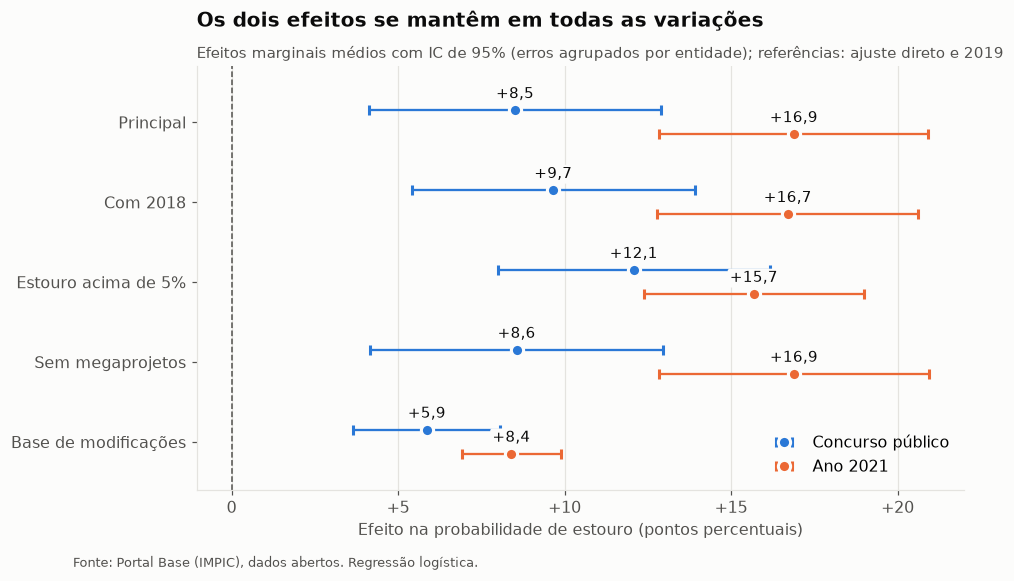

In [3]:
COR = {"azul": "#2a78d6", "laranja": "#eb6834", "texto": "#0b0b0b", "texto2": "#52514e",
       "grade": "#e4e3df", "fundo": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": COR["fundo"], "axes.facecolor": COR["fundo"], "axes.edgecolor": COR["grade"],
    "axes.labelcolor": COR["texto2"], "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlecolor": COR["texto"], "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "x", "grid.color": COR["grade"],
    "xtick.color": COR["texto2"], "ytick.color": COR["texto2"], "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

nomes = list(variacoes)
cores = {"Concurso público": COR["azul"], "Ano 2021": COR["laranja"]}
fig, ax = plt.subplots(figsize=(9, 5))
for i, (efeito, cor) in enumerate(cores.items()):
    g = robustez[robustez["efeito"] == efeito].set_index("variação").reindex(nomes)
    y = np.arange(len(nomes))[::-1] + (0.15 if i == 0 else -0.15)
    ax.errorbar(g["p.p."], y, xerr=[g["p.p."] - g["IC 2,5%"], g["IC 97,5%"] - g["p.p."]], fmt="o",
                color=cor, ecolor=cor, markersize=8, markeredgecolor=COR["fundo"], markeredgewidth=2,
                capsize=3, label=efeito)
    for xi, yi in zip(g["p.p."], y):
        if pd.notna(xi):
            ax.annotate(f"{xi:+.1f}".replace(".", ","), (xi, yi), textcoords="offset points", xytext=(0, 8),
                        ha="center", color=COR["texto"], fontsize=9.5, zorder=4,
                        bbox=dict(boxstyle="round,pad=0.15", facecolor=COR["fundo"], edgecolor="none"))
ax.axvline(0, color=COR["texto2"], linewidth=1, linestyle="--")
ax.set_yticks(np.arange(len(nomes))[::-1], nomes)
ax.set_ylim(-0.6, len(nomes) - 0.3)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}" if round(v) else "0")
ax.set_xlabel("Efeito na probabilidade de estouro (pontos percentuais)")
ax.legend(loc="lower right")
robusto = (robustez["IC 2,5%"] > 0).all()
ax.set_title("Os dois efeitos se mantêm em todas as variações" if robusto
             else "Nem todos os efeitos se mantêm em todas as variações", pad=26)
ax.text(0, 1.02, "Efeitos marginais médios com IC de 95% (erros agrupados por entidade); "
        "referências: ajuste direto e 2019", transform=ax.transAxes, color=COR["texto2"], fontsize=10)
fig.text(0, -0.03, "Fonte: Portal Base (IMPIC), dados abertos. Regressão logística.",
         color=COR["texto2"], fontsize=8.5)
fig.savefig(FIG / "06_robustez.png")
plt.show()

## 3. Viés de seleção: quem regista o fecho do contrato?

Os índices de custo só existem para os contratos com o fecho registado (cerca de 45%).
Se os contratos que registam o fecho forem diferentes dos outros, os resultados podem
estar distorcidos (hipótese H1).

O modelo abaixo usa **todas** as empreitadas de 2019–2022 e explica a probabilidade de o
contrato ter um CPIc válido, com as mesmas variáveis. Efeitos grandes indicam seleção.
A variação "Base de modificações", acima, já é uma resposta parcial: ela não depende do fecho.

In [4]:
selecao = janela(e).copy()
selecao["tem_fecho"] = selecao["CPIc"].notna()
ms = preparar(selecao, "tem_fecho")
mod_sel = ajustar(ms)
f = mod_sel.get_margeff(at="overall").summary_frame()
f.index = f.index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.(.+)\]", r"\1: \2", regex=True)
sel = (f[["dy/dx", "Conf. Int. Low", "Cont. Int. Hi."]] * 100).round(1)
sel.columns = ["efeito na prob. de ter fecho (p.p.)", "IC 2,5%", "IC 97,5%"]
print(f"Empreitadas 2019-2022: {len(ms):,} | com fecho registado: {ms['y'].mean():.1%}")
sel.loc[[i for i in sel.index if i.startswith(("procedimento", "ano", "log_"))]]

Empreitadas 2019-2022: 47,818 | com fecho registado: 42.6%


,efeito na prob. de ter fecho (p.p.),"IC 2,5%","IC 97,5%"
procedimento: Concurso público,-6.7,-13.4,0.1
procedimento: Consulta prévia,1.1,-3.1,5.2
procedimento: Outros,10.1,1.2,18.9
ano: 2020,6.1,1.6,10.6
ano: 2021,7.9,2.8,12.9
ano: 2022,4.1,-1.0,9.2
log_preco,-0.5,-5.1,4.2
log_prazo,3.0,-2.3,8.2


In [5]:
robustez.round(2).to_csv(RAIZ / "reports" / "robustez_efeitos.csv", sep=";", decimal=",", encoding="utf-8-sig")
sel.to_csv(RAIZ / "reports" / "selecao_fecho.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("Tabelas gravadas em reports/")

Tabelas gravadas em reports/
